# QE010: Monopoles in Quantum Spin Ice

**Counting ice, then watching a magnetic monopole move: quantum versus classical.**

In *spin ice*, tiny magnetic arrows sit on the bonds of a lattice and obey a local rule: at every corner, two arrows
point in and two point out, just like the hydrogen atoms around each oxygen in water ice. The rule leaves an enormous
number of allowed arrangements. Breaking it at one corner creates a defect that behaves like a **magnetic monopole**:
an isolated north or south pole that can travel through the material.

* **Part A (one exact answer, Euler-style):** count every allowed ice arrangement on an 8 × 8 lattice.
* **Part B1:** from these counts, recover the famous constant of square ice, $W = (4/3)^{3/2}$.
* **Part B2:** create a monopole, let it move either by quantum tunnelling or by classical random hopping, and
  measure how fast it spreads.

### Words used in this notebook

| term | meaning |
|---|---|
| **lattice / vertex / edge** | a square grid. Corners are **vertices**, the links between them are **edges**. Each edge carries one arrow |
| **torus (periodic lattice)** | the grid wraps around like a video-game screen: leaving on the right brings you back on the left |
| **ice rule** | at every vertex, exactly 2 arrows point in and 2 point out |
| **charge Q of a vertex** | (arrows in) − (arrows out). Ice: Q = 0 |
| **monopole** | a vertex with 3 in / 1 out (Q = +2) or 1 in / 3 out (Q = −2) |
| **Dirac string** | the trail of flipped arrows a monopole leaves behind as it moves |
| **transfer matrix** | a counting trick: build the lattice one row at a time and multiply small matrices instead of listing every arrangement |
| **entropy per vertex W** | if there are $N_\text{ice}$ arrangements on $N$ vertices, $W = N_\text{ice}^{1/N}$: the average number of choices per vertex |
| **transverse field Γ** | the quantum term that lets an arrow *tunnel* (flip) while staying in a superposition of both directions |
| **quantum annealer** | a machine whose qubits implement exactly this kind of arrow model, used to simulate spin ice |
| **MSD (mean squared displacement)** | the average squared distance the monopole has moved from its start |
| **diffusive / ballistic / super-diffusive** | MSD ∝ t (random walk), ∝ t² (straight-line motion), or in between |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs `numpy`, `scipy`, `pandas` and `matplotlib`, and runs in about a minute.

In [1]:
import itertools as it
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix, diags
from scipy.sparse.linalg import expm_multiply

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b"
rng = np.random.default_rng(10)                                  # random seed

## 1. Arrows and the ice rule

Every vertex $(i, j)$ owns two edges: the one to its right, with arrow $h_{ij} = \pm1$ (+1 = pointing right), and the
one above it, with arrow $v_{ij} = \pm1$ (+1 = pointing up). The charge of a vertex counts arrows in minus arrows out:

$$Q_{ij} = h_{i,j-1} + v_{i-1,j} - h_{ij} - v_{ij} .$$

The ice rule is $Q_{ij} = 0$ everywhere. The cell below counts ice arrangements by brute force for tiny lattices.

In [2]:
def brute_force_count(N):
    count = 0
    for bits in it.product([-1, 1], repeat=2 * N * N):
        h, v = np.array(bits).reshape(2, N, N)
        Q = np.roll(h, 1, axis=1) + np.roll(v, 1, axis=0) - h - v
        count += np.all(Q == 0)
    return count

for N in (2, 3):
    print(f"{N} x {N} torus: {2 ** (2 * N * N):>7,} arrow patterns, {brute_force_count(N):>4} obey the ice rule")

2 x 2 torus:     256 arrow patterns,   18 obey the ice rule


3 x 3 torus: 262,144 arrow patterns,  148 obey the ice rule


## Part A: how many ways to freeze ice?

Brute force dies quickly: an 8 × 8 torus has 128 arrows and $2^{128} \approx 3 \times 10^{38}$ patterns.

**Task:** count the ice arrangements on the **8 × 8 torus**, and report

$$A = \text{number of ice configurations on the } 8\times 8 \text{ torus}.$$

*Check value:* the 3 × 3 torus has **148**, matching the brute force above.

**Method: transfer matrix.** Describe one row by the vertical arrows entering it from below ($v_\text{in}$) and
leaving it at the top ($v_\text{out}$). Given both, the horizontal arrows in the row are forced vertex by vertex, since
$h_{j} = h_{j-1} + v_{\text{in},j} - v_{\text{out},j}$ must stay ±1 and wrap around consistently. So
$T[v_\text{in}, v_\text{out}]$ = number of valid rows, and the torus count is $\operatorname{Tr}(T^N)$.

In [3]:
def transfer_matrix(M):
    S = np.array(list(it.product([-1, 1], repeat=M)))              # all 2^M rows of vertical arrows
    step = S[:, None, :] - S[None, :, :]                           # v_in - v_out at each vertex
    T = np.zeros((2 ** M, 2 ** M), dtype=np.int64)
    for h0 in (-1, 1):                                             # arrow on the edge that wraps around
        h = h0 + np.cumsum(step, axis=-1)
        ok = np.all(np.abs(h) == 1, axis=-1) & (h[..., -1] == h0)
        T += ok
    return T

def torus_count(N, M):
    return int(np.trace(np.linalg.matrix_power(transfer_matrix(M), N)))

print(f"check, 3 x 3 torus: {torus_count(3, 3)}")
A = torus_count(8, 8)
print(f"\nANSWER  A = {A:,}")

check, 3 x 3 torus: 148

ANSWER  A = 2,901,094,068,042


## Part B1: the entropy of ice

How many choices does each vertex really have? Each vertex has $\binom42 = 6$ ice-allowed arrow patterns out of 16.

* **Pauling's estimate (1935)** treats vertices as independent: each has 4 arrows and each arrow is shared by 2
  vertices, so $W_\text{Pauling} = 2^2 \times \tfrac{6}{16} = 1.5$.
* **Lieb's exact result (1967)** accounts for all correlations: $W = (4/3)^{3/2} = 1.5396\ldots$

We can approach Lieb's value numerically in two ways: from the torus counts, $W_N = N_\text{ice}^{1/N^2}$, and, faster,
from long strips of width $M$, where $W_M = \lambda_\text{max}(M)^{1/M}$ with $\lambda_\text{max}$ the largest
eigenvalue of the transfer matrix.

In [4]:
W_lieb, W_pauling = (4 / 3) ** 1.5, 1.5
rows = []
for M in range(2, 11):
    lam = np.max(np.linalg.eigvals(transfer_matrix(M).astype(float)).real)
    rows.append({"size": M, "torus count": torus_count(M, M) if M <= 8 else None,
                 "W from torus": torus_count(M, M) ** (1 / M ** 2) if M <= 8 else None,
                 "W from strip": lam ** (1 / M)})
entropy = pd.DataFrame(rows).set_index("size")
entropy["torus count"] = entropy["torus count"].astype("Int64")
print(f"Pauling 1.5,  Lieb (4/3)^(3/2) = {W_lieb:.6f}")
entropy.round(6)

Pauling 1.5,  Lieb (4/3)^(3/2) = 1.539601


,torus count,W from torus,W from strip
size,,,
2,18,2.059767,1.732051
3,148,1.742369,1.587401
4,2970,1.648342,1.588816
5,143224,1.607832,1.556068
6,16448400,1.586529,1.561685
7,4484823396,1.573890,1.547908
8,2901094068042,1.565768,1.552088
9,<NA>,NaN,1.544606
10,<NA>,NaN,1.547615


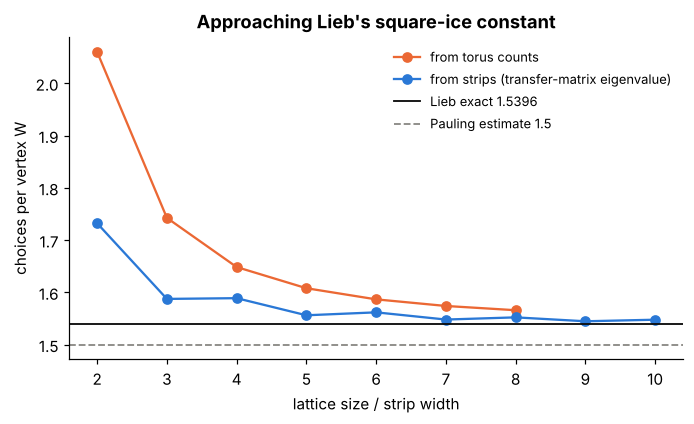

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.plot(entropy.index, entropy["W from torus"], "o-", color=ORANGE, label="from torus counts")
ax.plot(entropy.index, entropy["W from strip"], "o-", color=BLUE, label="from strips (transfer-matrix eigenvalue)")
ax.axhline(W_lieb, color=INK, lw=1.2, label=f"Lieb exact {W_lieb:.4f}")
ax.axhline(W_pauling, color=GRAY, ls="--", lw=1.2, label="Pauling estimate 1.5")
ax.set_xlabel("lattice size / strip width"); ax.set_ylabel("choices per vertex W")
ax.legend(frameon=False, fontsize=8.5); ax.set_title("Approaching Lieb's square-ice constant"); plt.show()

Strips converge much faster than tori: at width 9 the strip estimate is within 0.4% of Lieb's value, while the 8 × 8
torus is still 1.7% above it.
Pauling's simple estimate is only 2.6% too low, which is why it worked so well for real water ice.

## Part B2: a monopole on the move

**Energy.** We give every vertex the energy $J\,(Q/2)^2$, so ice costs nothing and a monopole costs $J$. Flipping one
arrow in an ice state turns its two end vertices into a +2 and a −2 monopole, a pair costing $2J$.

**Motion.** Once created, a monopole moves *without changing the energy*: flipping one of the arrows that point into a
+2 monopole moves the monopole to the next vertex. Each move flips one more arrow, and the trail of flipped arrows is
its **Dirac string**. Every allowed move costs nothing, so the monopole can move in two different ways:

* **classically:** each allowed flip happens at random with rate Γ (a random walk through the possible configurations);
* **quantum mechanically:** the transverse field Γ makes the flips *tunnel*, and the system evolves by the Schrödinger
  equation, $i\,\partial_t\psi = -\Gamma\,A\,\psi$, where $A$ connects configurations one flip apart. Different paths
  can now interfere.

**Set-up.**

* A random ice background on a 40 × 40 torus, made by flipping random closed loops of arrows. Loops never break the ice rule.
* Flip one arrow to make a monopole pair. The −2 partner is held fixed, the way device defects pin monopoles in
  experiments, and the +2 monopole moves.
* Build every configuration the moving monopole can reach in up to 17 hops, about 150,000–200,000 configurations
  (each one a full arrow pattern).
* Evolve exactly, both quantum and classical, and check that almost no probability reaches the 17-hop limit in the
  times we use.

In [6]:
L = 40

def vertex_edges(i, j):
    # (edge, neighbour, sign): sign = +1 if arrow value +1 on this edge points INTO vertex (i, j)
    return [((0, i, (j - 1) % L), (i, (j - 1) % L), +1), ((1, (i - 1) % L, j), ((i - 1) % L, j), +1),
            ((0, i, j), (i, (j + 1) % L), -1), ((1, i, j), ((i + 1) % L, j), -1)]

def charge(s, i, j):
    return sum(sign * s[e] for e, _, sign in vertex_edges(i, j))

def random_ice(loops=4000):
    s = np.ones((2, L, L), int)                                    # all right / all up: a valid ice state
    for _ in range(loops):                                         # follow out-arrows until a loop closes, flip it
        start = (rng.integers(L), rng.integers(L)); path, seen, edges = [start], {start: 0}, []
        while True:
            outs = [(e, w) for e, w, sign in vertex_edges(*path[-1]) if sign * s[e] == -1]
            e, w = outs[rng.integers(len(outs))]
            edges.append(e)
            if w in seen:
                for ee in edges[seen[w]:]:
                    s[ee] *= -1
                break
            seen[w] = len(path); path.append(w)
    assert all(charge(s, i, j) == 0 for i in range(L) for j in range(L))
    return s

def reachable_configurations(s_ice, max_hops):
    s0 = s_ice.copy(); s0[0, 0, 0] *= -1                           # flip one arrow: monopole pair at (0,0), (0,1)
    a, b = (0, 0), (0, 1)
    mobile, pinned = (a, b) if charge(s0, *a) == 2 else (b, a)
    index = {(mobile, frozenset()): 0}; position, hops, links = [mobile], [0], []
    frontier = [(mobile, frozenset())]
    for d in range(max_hops):
        new_frontier = []
        for m, flipped in frontier:
            s = s0.copy()
            for e in flipped:
                s[e] *= -1
            for e, w, sign in vertex_edges(*m):
                if sign * s[e] != 1 or w == pinned:                # only in-pointing arrows; never hit the partner
                    continue
                key = (w, flipped ^ {e})
                if key not in index:
                    index[key] = len(position); position.append(w); hops.append(d + 1); new_frontier.append(key)
                links.append((index[(m, flipped)], index[key]))
        frontier = new_frontier
    links = np.array(links); n = len(position)
    A_ = coo_matrix((np.ones(len(links)), (links[:, 0], links[:, 1])), shape=(n, n))
    A_ = ((A_ + A_.T) > 0).astype(float).tocsr()
    dr = (np.array(position) - np.array(mobile) + L // 2) % L - L // 2
    return A_, dr, np.array(hops)

In [7]:
MAX_HOPS, T_MAX, N_T, N_BACKGROUNDS = 17, 4.0, 40, 4
times = np.linspace(0.05, T_MAX, N_T)                              # in units of 1/Gamma
msd_q, msd_c, leak_q, leak_c = [], [], [], []
t0 = time.time()
for b in range(N_BACKGROUNDS):
    A_, dr, hops = reachable_configurations(random_ice(), MAX_HOPS)
    r2 = (dr ** 2).sum(1).astype(float)
    start = np.zeros(A_.shape[0]); start[0] = 1
    degree = np.asarray(A_.sum(1)).ravel()
    P_q = np.abs(expm_multiply(1j * A_, start.astype(complex), start=times[0], stop=times[-1], num=N_T)) ** 2
    P_c = expm_multiply(A_ - diags(degree), start, start=times[0], stop=times[-1], num=N_T)
    msd_q.append(P_q @ r2); msd_c.append(P_c @ r2)
    leak_q.append(P_q[-1][hops == MAX_HOPS].sum()); leak_c.append(P_c[-1][hops == MAX_HOPS].sum())
    if b == 0:
        snapshot = (dr, P_q[-1], P_c[-1])
    print(f"background {b + 1}: {A_.shape[0]:,} configurations; probability at the 17-hop limit at t = {T_MAX:g}: "
          f"quantum {leak_q[-1]:.4f}, classical {leak_c[-1]:.4f}")
msd_q, msd_c = np.mean(msd_q, 0), np.mean(msd_c, 0)
print(f"done in {time.time() - t0:.0f} s")

background 1: 149,790 configurations; probability at the 17-hop limit at t = 4: quantum 0.0000, classical 0.0002


background 2: 176,535 configurations; probability at the 17-hop limit at t = 4: quantum 0.0000, classical 0.0003


background 3: 187,954 configurations; probability at the 17-hop limit at t = 4: quantum 0.0000, classical 0.0003


background 4: 148,000 configurations; probability at the 17-hop limit at t = 4: quantum 0.0000, classical 0.0002
done in 25 s


In [8]:
def exponent(t, msd, t_min, t_max):
    m = (t >= t_min) & (t <= t_max)
    return np.polyfit(np.log(t[m]), np.log(msd[m]), 1)[0]

fit = pd.DataFrame({"early times (t < 0.3/Γ)": [exponent(times, msd_q, 0.05, 0.3), exponent(times, msd_c, 0.05, 0.3)],
                    "late window (1/Γ < t < 4/Γ)": [exponent(times, msd_q, 1, 4), exponent(times, msd_c, 1, 4)],
                    "MSD at t = 4/Γ": [msd_q[-1], msd_c[-1]]},
                   index=["quantum tunnelling", "classical hopping"]).round(3)
fit.index.name = "MSD ∝ t^α, fitted α"
fit

,early times (t < 0.3/Γ),late window (1/Γ < t < 4/Γ),MSD at t = 4/Γ
"MSD ∝ t^α, fitted α",,,
quantum tunnelling,2.001,1.471,16.722
classical hopping,1.021,1.006,8.919


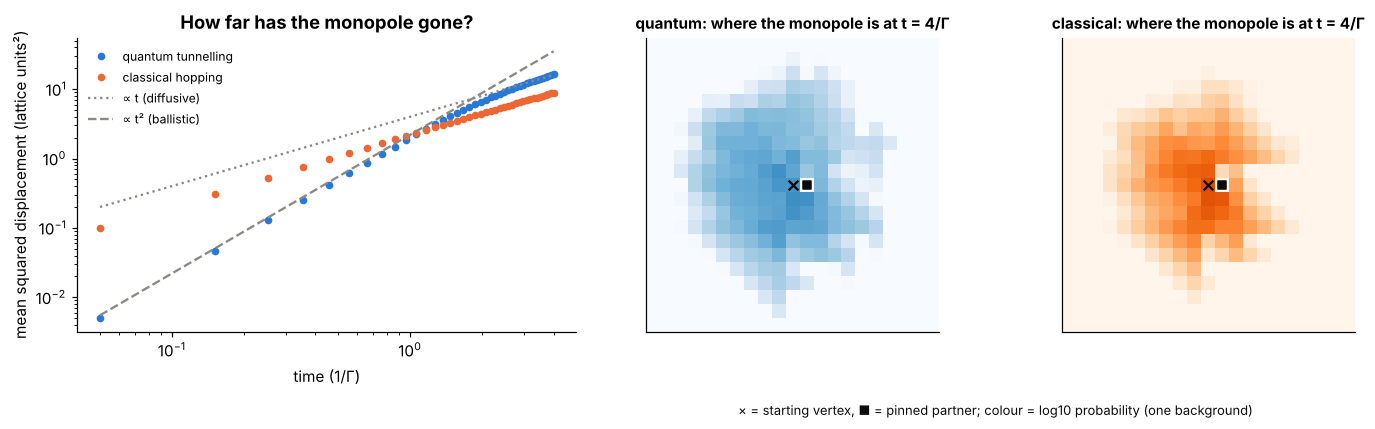

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.25, 1, 1]})
ax[0].loglog(times, msd_q, "o", ms=4, color=BLUE, label="quantum tunnelling")
ax[0].loglog(times, msd_c, "o", ms=4, color=ORANGE, label="classical hopping")
ax[0].loglog(times, 4 * times, ":", color=GRAY, label="∝ t (diffusive)")
ax[0].loglog(times, 2.2 * times ** 2, "--", color=GRAY, label="∝ t² (ballistic)")
ax[0].set_xlabel("time (1/Γ)"); ax[0].set_ylabel("mean squared displacement (lattice units²)")
ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("How far has the monopole gone?")
dr, pq, pc = snapshot
R = 10
for a_, p, title, col in [(ax[1], pq, "quantum", "Blues"), (ax[2], pc, "classical", "Oranges")]:
    grid = np.zeros((2 * R + 1, 2 * R + 1))
    keep = (np.abs(dr) <= R).all(1)
    np.add.at(grid, (dr[keep, 0] + R, dr[keep, 1] + R), p[keep])
    a_.imshow(np.log10(grid + 1e-6), cmap=col, vmin=-4, vmax=0, extent=[-R - .5, R + .5, R + .5, -R - .5])
    a_.scatter([0], [0], marker="x", color=INK, s=40); a_.scatter([1], [0], marker="s", color=INK, s=25)
    a_.set_title(f"{title}: where the monopole is at t = 4/Γ", fontsize=10)
    a_.set_xticks([]); a_.set_yticks([])
fig.text(0.70, 0.02, "× = starting vertex, ■ = pinned partner; colour = log10 probability (one background)",
         ha="center", fontsize=8.5, color=INK)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Reading the result.**

* At very early times the quantum monopole moves **ballistically** (α ≈ 2): the wave just starts to spread. The
  classical one is **diffusive** from the first moment (α ≈ 1).
* In the late window the quantum monopole is **super-diffusive**, with α between 1 and 2, while the classical one stays
  close to diffusive. By t = 4/Γ the quantum monopole's mean squared displacement is almost twice the classical one.
* The map shows why. The quantum wave spreads out evenly across the lattice. The classical walker stays concentrated
  near its start.

**Limits of this calculation.** Exact simulation follows the monopole for at most 17 hops. The printout above shows that
less than 0.1% of the probability reaches that limit by the last time used. Whether the super-diffusion lasts at long times, or
crosses over to ordinary diffusion as interference with the random background builds up, cannot be decided at this
size. That is an open question, and it is what quantum annealers with hundreds of qubits are now being used to test.

## Conclusions

1. **Ice is hugely degenerate.** The 8 × 8 torus allows **2,901,094,068,042** ice arrangements, about 1.57 choices
   per vertex, approaching Lieb's exact $(4/3)^{3/2} = 1.5396$ for large lattices.
2. **A transfer matrix turns an impossible count into a small matrix power.** $2^{128}$ patterns reduce to powers of
   a 256 × 256 matrix.
3. **Monopoles are free particles inside the ice.** Moving them costs no energy, so their motion is set entirely by
   how they hop. Quantum tunnelling spreads them super-diffusively over the times we can simulate exactly; classical
   hopping is close to diffusive.

**Try it yourself:** let both monopoles move, add a weak energy cost for long Dirac strings, or compare an ordered
background (start from `np.ones`, skip `random_ice`) with a random one.

### Further reading

* L. Pauling, *The structure and entropy of ice*, J. Am. Chem. Soc. 57, 2680 (1935).
* E. H. Lieb, *Residual entropy of square ice*, Phys. Rev. 162, 162 (1967).
* C. Castelnovo, R. Moessner, S. L. Sondhi, *Magnetic monopoles in spin ice*, Nature 451, 42 (2008).
* A. D. King et al., *Qubit spin ice*, Science 373, 576 (2021).
* K. Giergiel, P. Surówka, *Quantum-coherent regime of programmable dipolar spin ice*, arXiv:2603.28125 (2026).